# STEP 3 : เทรน YOLO 2 แบบ
**ไฟล์คู่กัน:** `03_train.py`

| แบบ | โมเดลตั้งต้น | yaml | task |
|---|---|---|---|
| Rectangle | `yolo26n.pt` | `rect.yaml` | detect |
| Polygon | `yolo26n-seg.pt` | `poly.yaml` | segment |

**Transfer Learning** = ไม่เริ่มจากศูนย์ โหลด weight ที่ฝึกบน COCO (80 คลาส) มาแล้ว แล้วฝึกต่อให้รู้จักแค่ 4 คลาสของเรา → ใช้ภาพน้อย เทรนเร็ว

In [1]:
# ===== ตั้งค่าเริ่มต้น (ทุก notebook ใช้เหมือนกัน) =====
import os, sys, json
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # กัน error OMP บน Windows

# notebook อยู่ใน final_dip/scripts/  ->  ย้ายไปทำงานที่ final_dip/ (path ทุกอย่างอ้างอิงจากที่นี่)
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
os.chdir(ROOT)
CLASSES = ["airplane", "boat", "car", "motorcycle"]
print("ทำงานที่:", ROOT)
import shutil
import pandas as pd, cv2
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO

ทำงานที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip


## 3.1 คำสั่งเทรน
เทรนเสร็จแล้ว (ใช้ CPU ประมาณ 40–50 นาทีต่อแบบ) จึงตั้ง `RUN_TRAIN = False` ไว้ ถ้าจะเทรนใหม่ให้เปลี่ยนเป็น `True`

พารามิเตอร์สำคัญ
- `epochs=20` ดูข้อมูลครบ 20 รอบ
- `imgsz=512` ย่อภาพเป็น 512 ก่อนเข้าโมเดล
- `batch=16` ภาพต่อ 1 step
- `patience=15` ถ้าไม่ดีขึ้น 15 รอบติดกันให้หยุด (early stopping)

In [2]:
RUN_TRAIN = False

CONFIGS = {"rect": ("yolo26n.pt", "rect.yaml"),
           "poly": ("yolo26n-seg.pt", "poly.yaml")}

def train(mode):
    pretrained, data_yaml = CONFIGS[mode]
    model = YOLO(pretrained)                          # 1) โหลด weight ตั้งต้น
    model.train(data=data_yaml, epochs=20, imgsz=512, batch=16, patience=15,
                device="cpu", project=str(ROOT / "runs"), name=mode, exist_ok=True, seed=42)
    shutil.copy(f"runs/{mode}/weights/best.pt", f"weights/{mode}_best.pt")   # 2) copy ไปให้เว็บใช้

if RUN_TRAIN:
    train("rect")
    train("poly")
else:
    print("ข้ามการเทรน -> ใช้ผลที่เทรนไว้แล้วใน runs/rect และ runs/poly")
    for m in CONFIGS:
        print(f"  weights/{m}_best.pt  {Path(f'weights/{m}_best.pt').stat().st_size/1e6:.1f} MB")

ข้ามการเทรน -> ใช้ผลที่เทรนไว้แล้วใน runs/rect และ runs/poly
  weights/rect_best.pt  5.4 MB
  weights/poly_best.pt  6.5 MB


## 3.2 กราฟระหว่างเทรน (จาก `results.csv`)
- **loss** (ความผิดพลาด) ต้อง **ลดลง** → โมเดลเรียนรู้ได้
- **mAP50** (ความแม่น) ต้อง **เพิ่มขึ้น**

In [3]:
res = {m: pd.read_csv(f"runs/{m}/results.csv") for m in ["rect", "poly"]}
for m, df in res.items():
    df.columns = df.columns.str.strip()
cols = ["epoch", "train/box_loss", "val/box_loss", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)"]
print("RECT : 5 epoch สุดท้าย")
res["rect"][cols].tail(5)

RECT : 5 epoch สุดท้าย


,epoch,train/box_loss,val/box_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B)
15,16,0.91462,1.20848,0.73910,0.66571,0.73329
16,17,0.86280,1.16515,0.81953,0.64218,0.74328
17,18,0.87072,1.15037,0.81568,0.63956,0.74697
18,19,0.85040,1.10367,0.77865,0.68069,0.74535
19,20,0.83970,1.09936,0.75165,0.68406,0.74182


In [4]:
print("POLY : 5 epoch สุดท้าย")
res["poly"][cols + ["metrics/mAP50(M)"]].tail(5)

POLY : 5 epoch สุดท้าย


,epoch,train/box_loss,val/box_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50(M)
15,16,0.94716,1.17888,0.76871,0.63790,0.71931,0.67647
16,17,0.88820,1.18986,0.81698,0.64964,0.72841,0.69213
17,18,0.89618,1.18230,0.79771,0.64232,0.73063,0.71031
18,19,0.88508,1.17113,0.79461,0.66711,0.74939,0.71794
19,20,0.84730,1.15662,0.78519,0.65716,0.74573,0.71911


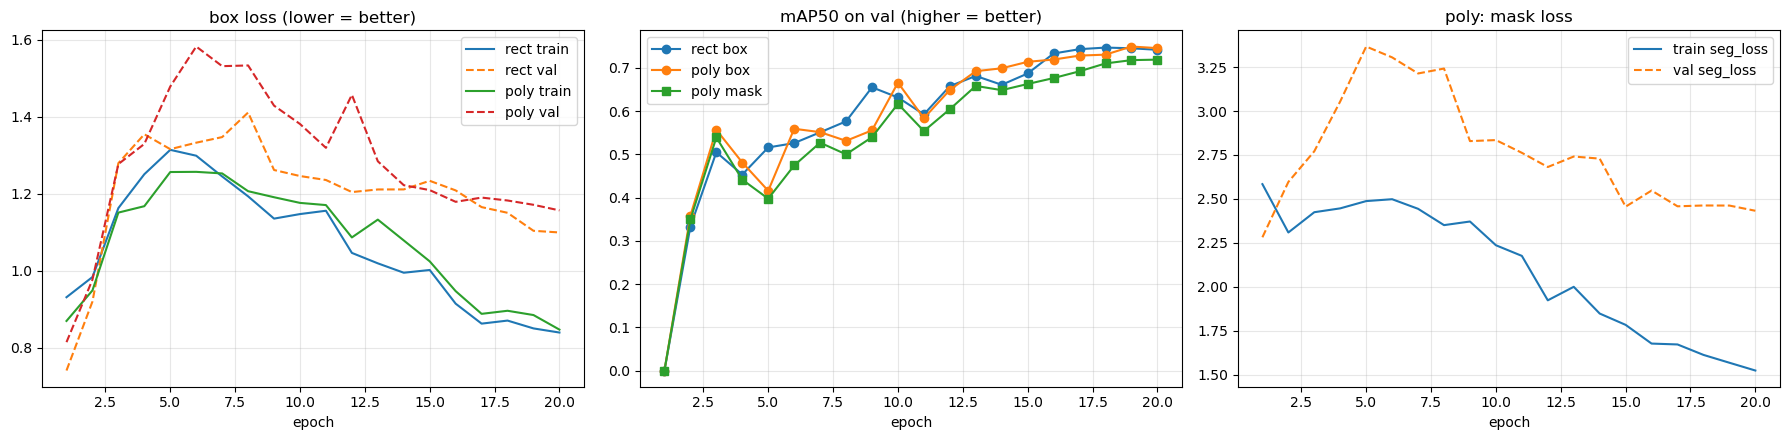

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for m, df in res.items():
    ax[0].plot(df["epoch"], df["train/box_loss"], label=f"{m} train")
    ax[0].plot(df["epoch"], df["val/box_loss"], "--", label=f"{m} val")
    ax[1].plot(df["epoch"], df["metrics/mAP50(B)"], marker="o", label=f"{m} box")
ax[1].plot(res["poly"]["epoch"], res["poly"]["metrics/mAP50(M)"], marker="s", label="poly mask")
ax[2].plot(res["poly"]["epoch"], res["poly"]["train/seg_loss"], label="train seg_loss")
ax[2].plot(res["poly"]["epoch"], res["poly"]["val/seg_loss"], "--", label="val seg_loss")
ax[0].set_title("box loss (lower = better)"); ax[1].set_title("mAP50 on val (higher = better)")
ax[2].set_title("poly: mask loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

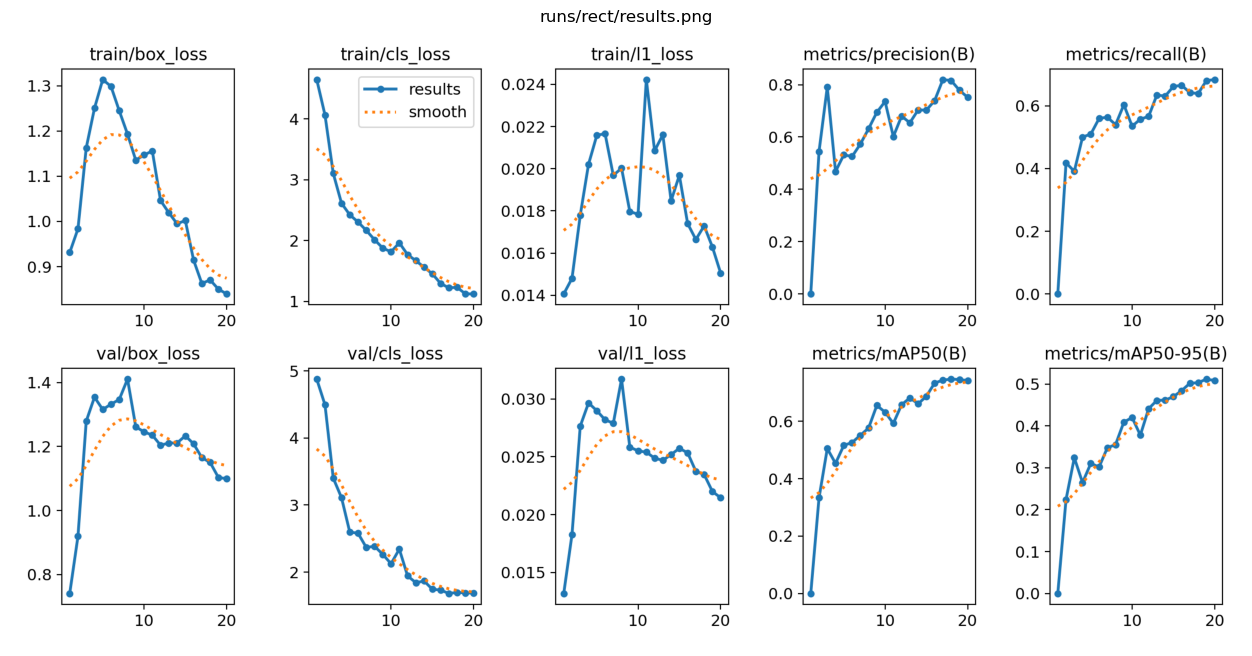

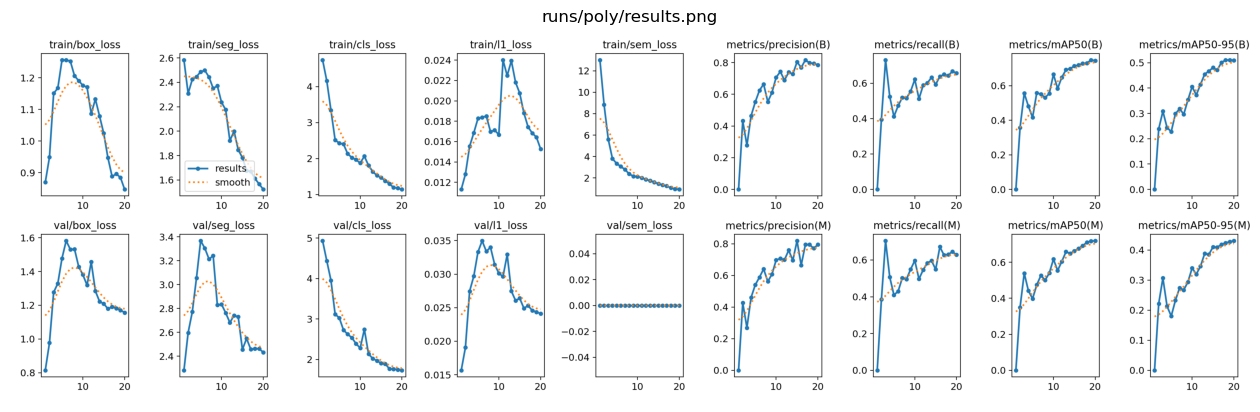

In [6]:
# กราฟที่ ultralytics วาดให้อัตโนมัติ
def show(path, title, size=(16, 8)):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

show("runs/rect/results.png", "runs/rect/results.png")
show("runs/poly/results.png", "runs/poly/results.png")

## 3.3 Confusion Matrix
แถว = คลาสที่โมเดลทาย, คอลัมน์ = คลาสจริง · **เส้นทแยงยิ่งเข้ม = ทายถูกเยอะ**
`background` = วัตถุที่โมเดลมองไม่เห็น หรือทายว่ามีวัตถุในที่ที่ไม่มี

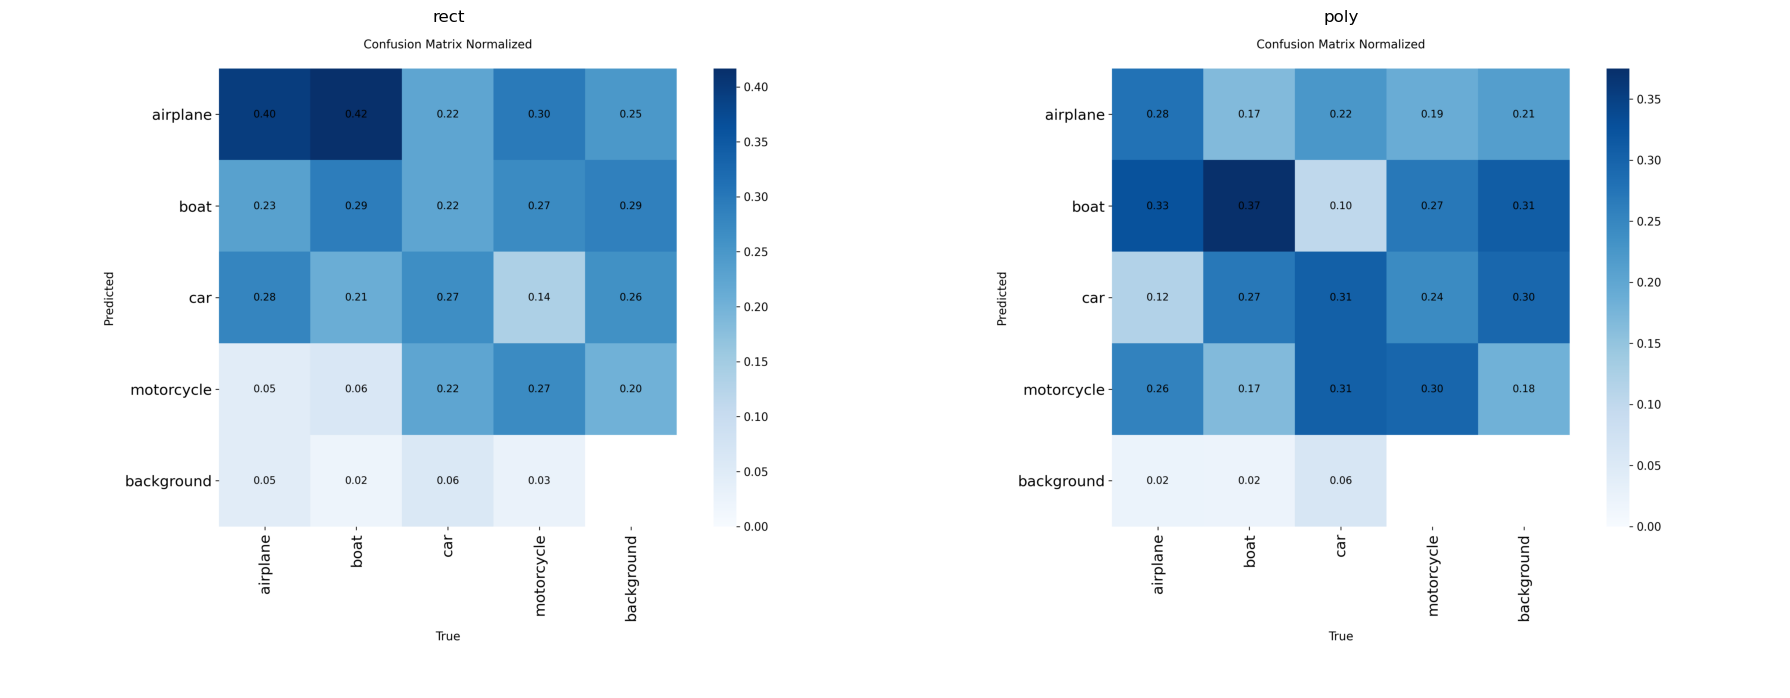

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, m in zip(ax, ["rect", "poly"]):
    a.imshow(cv2.cvtColor(cv2.imread(f"runs/{m}/confusion_matrix_normalized.png"), cv2.COLOR_BGR2RGB))
    a.set_title(m); a.axis("off")
plt.tight_layout(); plt.show()

## 3.4 ตัวอย่างภาพ validation : label จริง (ซ้าย) vs ที่โมเดลทาย (ขวา)

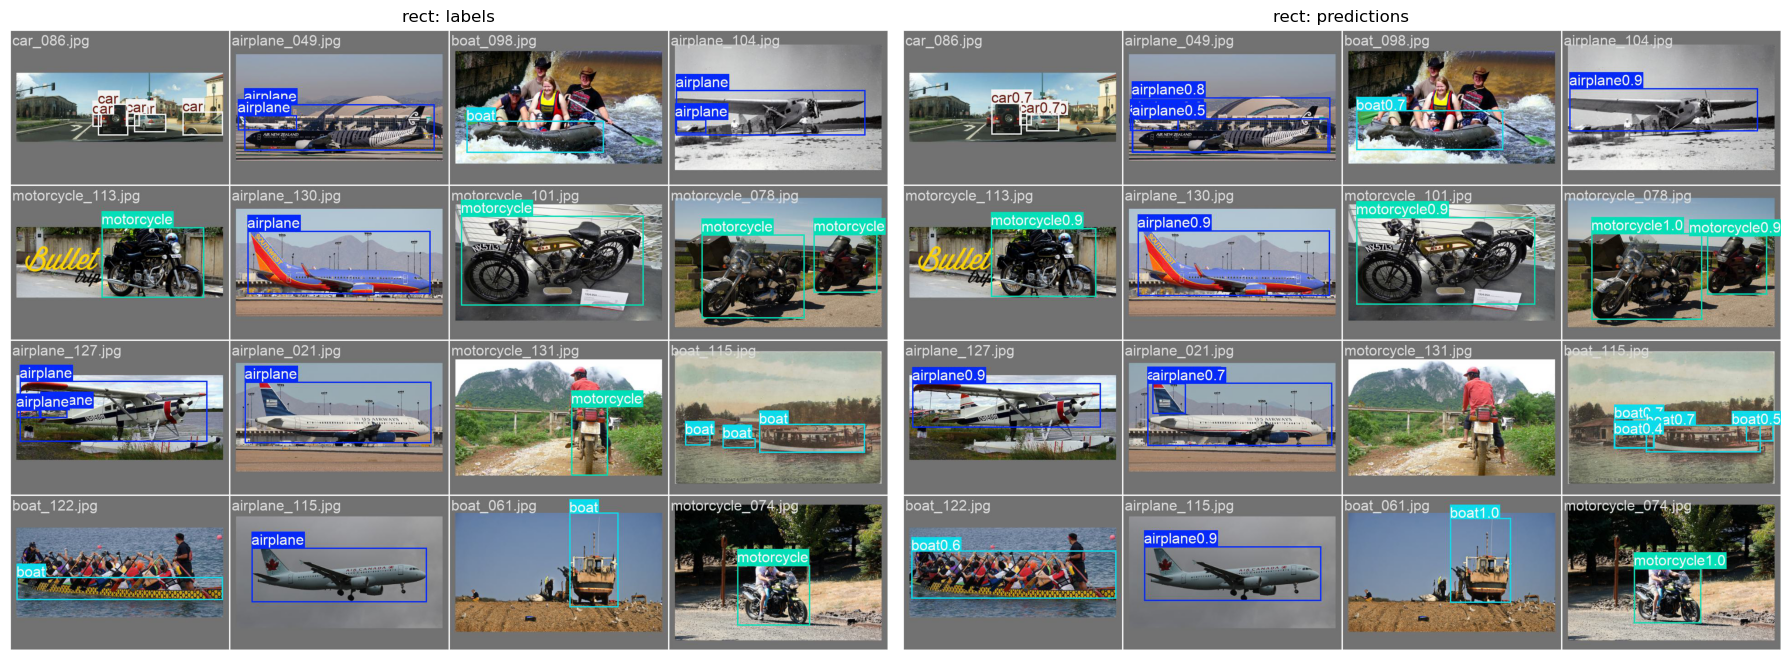

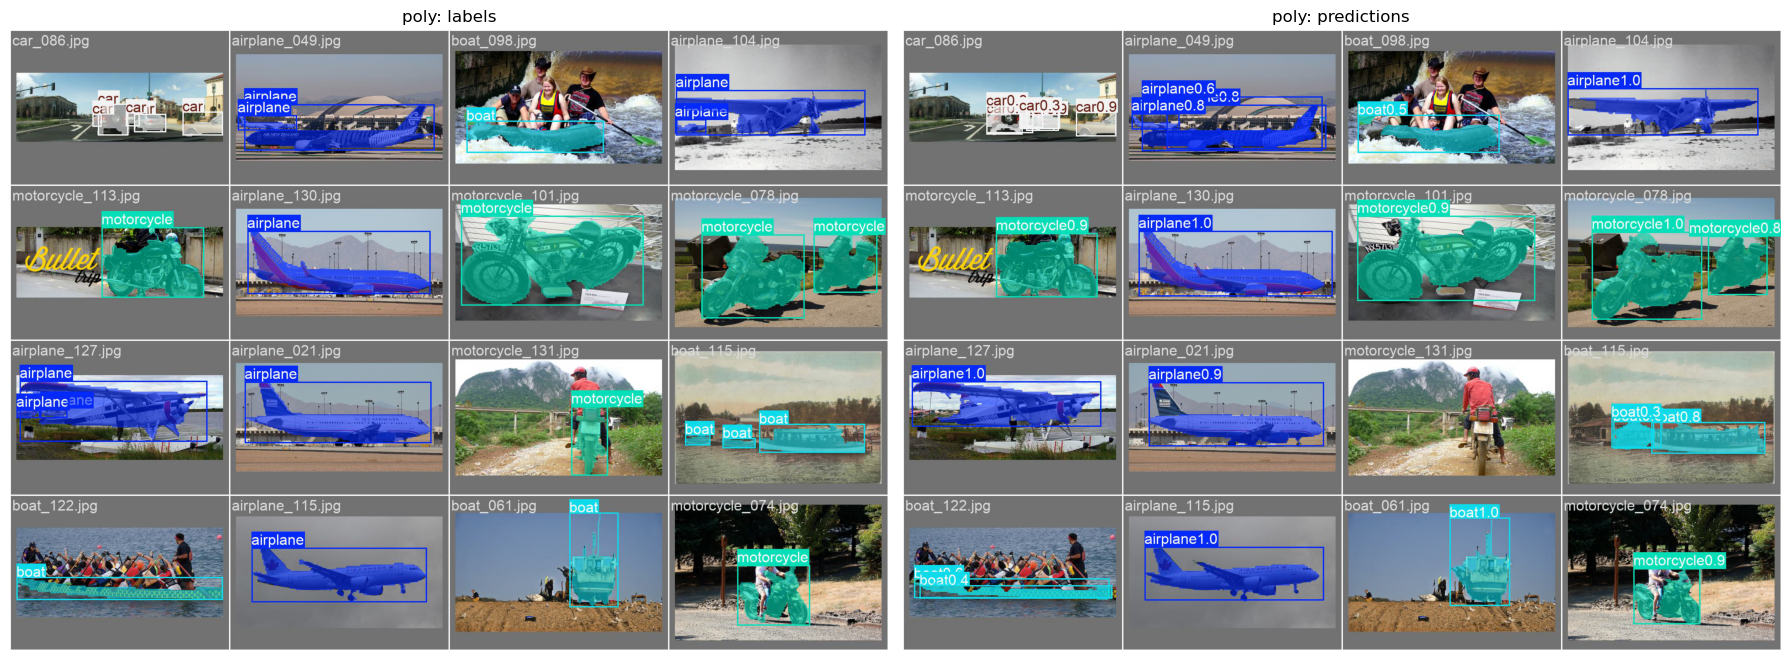

In [8]:
for m in ["rect", "poly"]:
    fig, ax = plt.subplots(1, 2, figsize=(18, 9))
    ax[0].imshow(cv2.cvtColor(cv2.imread(f"runs/{m}/val_batch0_labels.jpg"), cv2.COLOR_BGR2RGB)); ax[0].set_title(f"{m}: labels")
    ax[1].imshow(cv2.cvtColor(cv2.imread(f"runs/{m}/val_batch0_pred.jpg"), cv2.COLOR_BGR2RGB)); ax[1].set_title(f"{m}: predictions")
    ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()

## 3.5 วัดผลกับชุด test (ภาพที่โมเดลไม่เคยเห็นตอนเทรน)
- **mAP50** = ทายตำแหน่งถูก (ซ้อนทับ ≥ 50%) และคลาสถูก
- **mAP50-95** = เข้มงวดกว่า (เฉลี่ยตั้งแต่ซ้อนทับ 50% ถึง 95%)

In [9]:
rows = []
for m, data_yaml in [("rect", "rect.yaml"), ("poly", "poly.yaml")]:
    met = YOLO(f"weights/{m}_best.pt").val(data=data_yaml, split="test", imgsz=512, device="cpu",
                                           project=str(ROOT / "runs"), name=f"{m}_test", exist_ok=True, verbose=False, plots=False)
    for i, cls in met.names.items():
        row = {"model": m, "class": cls, "box mAP50": round(met.box.ap50[i], 3), "box mAP50-95": round(met.box.ap[i], 3)}
        if m == "poly":
            row["mask mAP50"] = round(met.seg.ap50[i], 3)
        rows.append(row)
    rows.append({"model": m, "class": "ALL", "box mAP50": round(met.box.map50, 3), "box mAP50-95": round(met.box.map, 3),
                 **({"mask mAP50": round(met.seg.map50, 3)} if m == "poly" else {})})
pd.DataFrame(rows).fillna("-")

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


YOLO26n summary (fused): 120 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs


WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 12.45.1 MB/s, size: 152.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning C:\code\ImageProcessing\yolo\yolo_lab\final_dip\datasets\yolo_rect\test\labels... 36 images, 0 backgrounds, 0 corrupt: 60% ━━━━━━━───── 36/60 105.9it/s 0.1s<0.2s

val: Scanning C:\code\ImageProcessing\yolo\yolo_lab\final_dip\datasets\yolo_rect\test\labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 378.8it/s 0.2s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 75% ━━━━━━━━━─── 3/4 2.3s/it 4.5s<2.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5s/it 6.0s

                   all         60         97      0.833      0.717      0.791      0.557      0.846      0.726      0.798      0.468


Speed: 1.2ms preprocess, 70.2ms inference, 0.0ms loss, 5.0ms postprocess per image


,model,class,box mAP50,box mAP50-95,mask mAP50
0,rect,airplane,0.974,0.866,-
1,rect,boat,0.674,0.335,-
2,rect,car,0.743,0.470,-
3,rect,motorcycle,0.883,0.683,-
4,rect,ALL,0.818,0.588,-
5,poly,airplane,0.954,0.837,0.954
6,poly,boat,0.602,0.313,0.591
7,poly,car,0.718,0.440,0.772
8,poly,motorcycle,0.891,0.638,0.877
9,poly,ALL,0.791,0.557,0.798
